# 07 · Evaluating a RAG System

Until now we judged results by reading them. That does not scale, and it hides the most important property
of a RAG system: **whether it is getting better or worse**. Every change you make (a new chunk size, an
embedding model, a prompt, a threshold) fixes some questions and silently breaks others. Without a fixed
battery of questions with known answers you are navigating by feel.

This module builds that battery properly, grades it automatically, shows where the automatic grade is
**wrong** (it will be), measures how much evidence a battery of this size can really give, and ends with a
before/after comparison on questions written *after* the fix.

**You will learn**
1. What a good question battery contains: coverage, paraphrases, exact identifiers and **traps**
2. References taken from the source, never from the system under test
3. An automatic grader (required facts, forbidden claims, right source) and two ways it fails
4. Rule-based faithfulness and citation checks, and what they cannot see
5. Retrieval metrics (hit@k, MRR) next to answer metrics (correctness, refusal precision and recall)
6. Bootstrap confidence intervals, and how many questions you need to tell two systems apart
7. A before/after comparison where the second set was **not** used to build the fix

### Picture: a change is judged on a fixed battery

Read it left to right. A change to the system goes through the **same** battery of questions with known
answers. Each question lands in one of three boxes (newly right, unchanged, newly wrong), and the result is
a score **with an interval**, not a single number. The numbers are the ones this notebook produces further down.

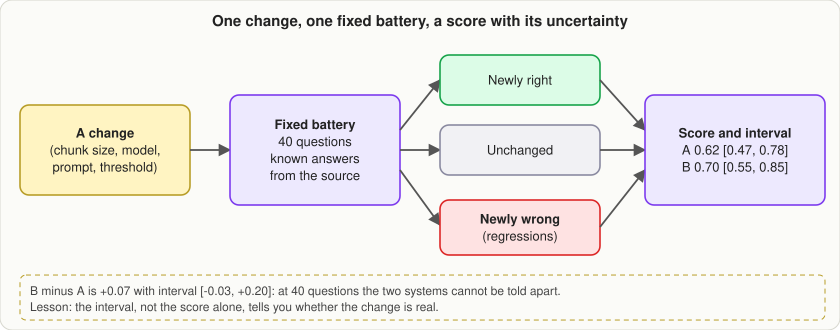

In [1]:
from IPython.display import SVG, display
import html as _h

_COL = {  # fill, stroke  (light cards with dark text: readable in light and dark themes)
    "gold": ("#fff4c2", "#b89d28"), "blue": ("#dbeafe", "#3b82f6"), "green": ("#dcfce7", "#16a34a"),
    "red": ("#fee2e2", "#dc2626"), "grey": ("#f1f1f4", "#8a8aa0"), "violet": ("#ede9fe", "#7c3aed"),
}

def diagram(width, height, items, title=None):
    # items: ("box", x, y, w, h, "text\nmore text", colour) | ("arrow", x1, y1, x2, y2, "label") |
    #        ("text", x, y, "text", size, "start|middle|end") | ("note", x, y, w, h, "text")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" '
           f'font-family="Helvetica, Arial, sans-serif">',
           '<defs><marker id="ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" '
           'orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#555"/></marker></defs>',
           f'<rect width="{width}" height="{height}" rx="12" fill="#fbfbf8" stroke="#d8d8cf"/>']
    if title:
        out.append(f'<text x="{width / 2}" y="26" text-anchor="middle" font-size="15" font-weight="700" fill="#222">{_h.escape(title)}</text>')
    for it in items:
        kind = it[0]
        if kind == "box":
            _, x, y, w, h, text, col = it
            fill, stroke = _COL[col]
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="9" fill="{fill}" stroke="{stroke}" stroke-width="1.6"/>')
            lines = text.split("\n")
            y0 = y + h / 2 - (len(lines) - 1) * 8.5 + 4.5
            for k, ln in enumerate(lines):
                bold = ' font-weight="700"' if k == 0 and len(lines) > 1 else ""
                out.append(f'<text x="{x + w / 2}" y="{y0 + k * 17}" text-anchor="middle" font-size="13" fill="#222"{bold}>{_h.escape(ln)}</text>')
        elif kind == "arrow":
            _, x1, y1, x2, y2, label = it
            out.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#555" stroke-width="1.8" marker-end="url(#ah)"/>')
            if label:
                out.append(f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 6}" text-anchor="middle" font-size="11.5" fill="#555">{_h.escape(label)}</text>')
        elif kind == "text":
            _, x, y, text, size, anchor = it
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x}" y="{y + k * (size + 4)}" text-anchor="{anchor}" font-size="{size}" fill="#333">{_h.escape(ln)}</text>')
        elif kind == "note":
            _, x, y, w, h, text = it
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="6" fill="none" stroke="#b89d28" stroke-dasharray="5 4"/>')
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x + 10}" y="{y + 20 + k * 16}" font-size="12" fill="#444">{_h.escape(ln)}</text>')
    out.append("</svg>")
    display(SVG("".join(out)))


diagram(840, 330, [
    ("box", 20, 105, 170, 90, "A change\n(chunk size, model,\nprompt, threshold)", "gold"),
    ("arrow", 190, 150, 230, 150, ""),
    ("box", 230, 95, 170, 110, "Fixed battery\n40 questions\nknown answers\nfrom the source", "violet"),
    ("arrow", 400, 130, 440, 80, ""),
    ("arrow", 400, 150, 440, 150, ""),
    ("arrow", 400, 170, 440, 225, ""),
    ("box", 440, 55, 160, 50, "Newly right", "green"),
    ("box", 440, 125, 160, 50, "Unchanged", "grey"),
    ("box", 440, 200, 160, 55, "Newly wrong\n(regressions)", "red"),
    ("arrow", 600, 80, 645, 130, ""),
    ("arrow", 600, 150, 645, 150, ""),
    ("arrow", 600, 227, 645, 170, ""),
    ("box", 645, 95, 180, 110, "Score and interval\nA 0.62 [0.47, 0.78]\nB 0.70 [0.55, 0.85]", "violet"),
    ("note", 20, 275, 805, 45, "B minus A is +0.07 with interval [-0.03, +0.20]: at 40 questions the two systems cannot be told apart.\nLesson: the interval, not the score alone, tells you whether the change is real."),
], "One change, one fixed battery, a score with its uncertainty")

## 1. The battery

Forty questions in two sets over the Harbourview handbook. Each carries:

* the **gold passage** that holds the answer (or `None` when the handbook cannot answer);
* **required facts** as regular expressions the answer must contain, and **forbidden claims** it must not;
* a **kind**: `direct`, `paraphrase`, `identifier`, or `trap`.

**Set 1** (20 questions) is what we look at while building. **Set 2** (20 questions) is written *afterwards*
and only used to check that a fix generalises. The **traps** are questions a careless system answers
confidently and wrongly: a turbine that does not exist (`HV99`), and a result the handbook never reports (last
month's availability, when it only states a *target*). A battery without traps rewards systems that never
say "I do not know".

The references come from reading the handbook (the data behind the system), **never from running the
system**. A reference copied from the system's output measures only that the system agrees with itself.

In [2]:
# The Harbourview handbook: 22 passages, fictional, written for this course
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

In [3]:
import re, math, time, textwrap
import numpy as np
import matplotlib.pyplot as plt

# (id, question, gold passage or None, required fact patterns, forbidden patterns, kind)
SET1 = [
    ("s01", "What wave height stops the crew boats from sailing?", "p02", [r"1\.5 ?m"], [], "direct"),
    ("s02", "How often is the gearbox oil sampled?", "p07", [r"six months"], [], "direct"),
    ("s03", "Who may work alone inside a nacelle?", "p03", [r"forbidden"], [], "paraphrase"),
    ("s04", "What is the rotor diameter of a turbine?", "p04", [r"164 ?m"], [], "direct"),
    ("s05", "What do I do if the pitch fault comes back after a reset?", "p10", [r"replace the hydraulic accumulator"], [], "direct"),
    ("s06", "When must a Level 3 alarm be attended on site?", "p09", [r"24 hours"], [], "direct"),
    ("s07", "How soon must an injury be reported?", "p19", [r"one hour"], [], "direct"),
    ("s08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", [r"300 ?MW"], [r"8\.0 ?MW"], "paraphrase"),
    ("s09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", [r"HV01 to HV08"], [], "paraphrase"),
    ("s10", "How many spare wind vanes are kept in stock?", "p16", [r"four wind vanes"], [], "direct"),
    ("s11", "What qualification do I need before getting on the boat?", "p01", [r"GWO Basic Safety Training"], [], "paraphrase"),
    ("s12", "When can the turbines restart after a blackout?", "p12", [r"10 minutes"], [], "paraphrase"),
    ("s13", "When can a helicopter be used?", "p17", [r"medical evacuation"], [], "direct"),
    ("s14", "What happens when a dolphin is seen near the piling work?", "p13", [r"pause"], [], "paraphrase"),
    ("s15", "What is the price of electricity per MWh?", None, [], [], "trap"),
    ("s16", "Who is the chief executive of the operating company?", None, [], [], "trap"),
    ("s17", "What is the rated power of turbine HV99?", None, [], [], "trap"),
    ("s18", "What availability did the farm achieve last month?", None, [], [], "trap"),
    ("s19", "How many turbines does the farm have?", "p04", [r"40 turbines"], [], "direct"),
    ("s20", "What is the cut-in wind speed?", "p04", [r"3 ?m/s"], [], "direct"),
]
SET2 = [
    ("t01", "Are boats cancelled when the sea is too rough?", "p02", [r"1\.5 ?m"], [], "paraphrase"),
    ("t02", "Can I go up the tower alone to fix something?", "p03", [r"forbidden"], [], "paraphrase"),
    ("t03", "How big are the blades?", "p04", [r"164 ?m"], [], "paraphrase"),
    ("t04", "Who do I call in the middle of the night about an accident?", "p18", [r"control room line"], [], "paraphrase"),
    ("t05", "What if the oil in the gearbox gets dirty?", "p07", [r"filter change"], [], "paraphrase"),
    ("t06", "Do you stop work when whales or seals swim close?", "p13", [r"pause"], [], "paraphrase"),
    ("t07", "How much spare equipment is kept on shore?", "p16", [r"two pitch accumulators"], [], "paraphrase"),
    ("t08", "Is the farm allowed to produce at full output?", "p21", [r"300 ?MW"], [], "paraphrase"),
    ("t09", "What should new colleagues do before their first trip?", "p22", [r"induction"], [], "paraphrase"),
    ("t10", "How should rubbish and old oil be handled?", "p15", [r"brought ashore"], [], "paraphrase"),
    ("t11", "What does code PF-203 mean?", "p10", [r"low accumulator pressure"], [], "identifier"),
    ("t12", "alarm YW-110", "p11", [r"8 degrees"], [], "identifier"),
    ("t13", "ISO 4406 18/16/13", "p07", [r"filter change"], [], "identifier"),
    ("t14", "Where is OSS1?", "p05", [r"centre"], [], "identifier"),
    ("t15", "66 kV cables", "p21", [r"two cables"], [], "identifier"),
    ("t16", "What is the stock price of the operating company?", None, [], [], "trap"),
    ("t17", "What is the rotor diameter of turbine HV77?", None, [], [], "trap"),
    ("t18", "What was the monthly availability in July?", None, [], [], "trap"),
    ("t19", "How many people work on the farm?", None, [], [], "trap"),
    ("t20", "What is the cut-out wind speed?", None if False else "p04", [r"25 ?m/s"], [], "direct"),
]
BATTERY = SET1 + SET2
ids = [p[0] for p in PASSAGES]
chunks = [f"{section}. {text}" for _, section, text in PASSAGES]
from collections import Counter
print(len(BATTERY), "questions;", Counter(q[5] for q in BATTERY), "; unanswerable:", sum(q[2] is None for q in BATTERY))

40 questions; Counter({'paraphrase': 16, 'direct': 11, 'trap': 8, 'identifier': 5}) ; unanswerable: 8


/home/patito/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 2. Two systems to compare

The systems under test are the ones from modules 01 and 02, kept small so the evaluation is the star:

* **System A**: BM25 retrieval.
* **System B**: hybrid retrieval, BM25 and MiniLM embeddings fused by weighted Reciprocal Rank Fusion
  (BM25 weight 0.25, the best setting we found in module 02).

Both use the same deterministic **extractive generator** (quote the top passage and cite it as `[1]`) and refuse
when retrieval looks too weak. A system returns the
answer, the passage it cited, and whether it refused.

### Picture: how the data flows in this module

The handbook is the source of the references. The battery feeds the two systems, each system returns an
answer, the passage it cited and whether it refused, and grader v2 turns those into the metrics and the
interval you will compute below.

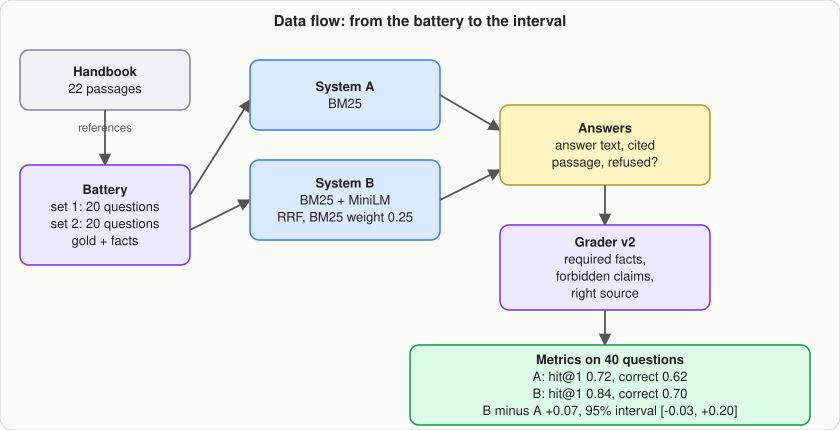

In [4]:
diagram(840, 430, [
    ("box", 20, 50, 170, 60, "Handbook\n22 passages", "grey"),
    ("arrow", 105, 110, 105, 165, "references"),
    ("box", 20, 165, 170, 100, "Battery\nset 1: 20 questions\nset 2: 20 questions\ngold + facts", "violet"),
    ("arrow", 190, 195, 250, 100, ""),
    ("arrow", 190, 230, 250, 200, ""),
    ("box", 250, 60, 190, 70, "System A\nBM25", "blue"),
    ("box", 250, 160, 190, 80, "System B\nBM25 + MiniLM\nRRF, BM25 weight 0.25", "blue"),
    ("arrow", 440, 95, 500, 130, ""),
    ("arrow", 440, 200, 500, 170, ""),
    ("box", 500, 105, 210, 80, "Answers\nanswer text, cited\npassage, refused?", "gold"),
    ("arrow", 605, 185, 605, 225, ""),
    ("box", 500, 225, 210, 85, "Grader v2\nrequired facts,\nforbidden claims,\nright source", "violet"),
    ("arrow", 605, 310, 605, 345, ""),
    ("box", 410, 345, 400, 80, "Metrics on 40 questions\nA: hit@1 0.72, correct 0.62\nB: hit@1 0.84, correct 0.70\nB minus A +0.07, 95% interval [-0.03, +0.20]", "green"),
], "Data flow: from the battery to the interval")

In [5]:
STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
def tokens(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.tf = [{} for _ in docs]
        for i, d in enumerate(docs):
            for t in tokens(d):
                self.tf[i][t] = self.tf[i].get(t, 0) + 1
        self.len = np.array([sum(tf.values()) for tf in self.tf], dtype=float); self.avg = self.len.mean()
        df = {}
        for tf in self.tf:
            for t in tf:
                df[t] = df.get(t, 0) + 1
        self.idf = {t: math.log(1 + (len(docs) - c + 0.5) / (c + 0.5)) for t, c in df.items()}
    def scores(self, query):
        s = np.zeros(len(self.tf))
        for t in set(tokens(query)):
            if t in self.idf:
                for i, tf in enumerate(self.tf):
                    f = tf.get(t, 0)
                    if f:
                        s[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return s

from sentence_transformers import SentenceTransformer
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
E = model.encode(chunks, normalize_embeddings=True)
bm25 = BM25(chunks)
sem = lambda q: E @ model.encode(q, normalize_embeddings=True)

def rrf(scorers, weights, k=60):
    def fused(q):
        total = np.zeros(len(ids))
        for sc, w in zip(scorers, weights):
            for rank, i in enumerate(np.argsort(-sc(q)), start=1):
                total[i] += w / (k + rank)
        return total
    return fused

def quote(idx):
    return chunks[idx].split(". ", 1)[1]

def build_system(scorer, refuse, expand=None, entity_guard=False):
    def system(question):
        query = expand(question) if expand else question
        if entity_guard:
            for hv in re.findall(r"\bHV(\d+)\b", question):
                if not 1 <= int(hv) <= 40:
                    return dict(refused=True, cited=None, answer="That turbine does not exist in this farm.", ranking=[])
        s = scorer(query)
        order = np.argsort(-s)
        if refuse(question, query):
            return dict(refused=True, cited=None, answer="I cannot find that in the handbook.", ranking=[ids[i] for i in order])
        top = int(order[0])
        return dict(refused=False, cited=ids[top], answer=f"{quote(top)} [1]", ranking=[ids[i] for i in order])
    return system

A = build_system(bm25.scores, lambda q, e: bm25.scores(e).max() < 1.0)
hybrid = rrf([bm25.scores, sem], [0.25, 1.0])
B = build_system(hybrid, lambda q, e: bm25.scores(e).max() < 1.0 and sem(e).max() < 0.30)
for name, sys_ in [("A", A), ("B", B)]:
    r = sys_("What wave height stops the crew boats from sailing?")
    print(name, r["cited"], "|", r["answer"])

/home/patito/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3169.27it/s]

A p02 | Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later. [1]
B p02 | Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later. [1]


## 3. The automatic grader, version 1: regular expressions

The cheapest grader needs no model: an answer to an answerable question is **correct** when it contains
**every required fact** and **no forbidden claim**; an answer to a trap is correct when the system
**refuses**. It is fast, deterministic and free, and you can run it on every commit. Its limits are the rest
of this section.

In [6]:
# Version 1 patterns: written quickly, as one does. Two of them are flawed on purpose (see section 4).
V1_OVERRIDES = {
    "s08": ([r"\d+(\.\d+)? ?MW"], []),        # "some number of MW": weak, and no forbidden claim
    "s12": ([r"10 min\b"], []),               # \b after "min": too strict, the text says "minutes"
}

def grade_v1(q, out):
    qid, question, gold, req, forbid, kind = q
    if gold is None:
        return "correct" if out["refused"] else "wrong"
    if out["refused"]:
        return "missed"
    req, forbid = V1_OVERRIDES.get(qid, (req, forbid))
    ok = all(re.search(p, out["answer"], re.I) for p in req) and not any(re.search(p, out["answer"], re.I) for p in forbid)
    return "correct" if ok else "wrong"

def run_all(system, battery=BATTERY):
    return {q[0]: system(q[1]) for q in battery}

runs = {"A": run_all(A), "B": run_all(B)}
def summary(grader, runs_, battery=BATTERY):
    return {name: sum(grader(q, out[q[0]]) == "correct" for q in battery) for name, out in runs_.items()}

print("grader v1, correct out of", len(BATTERY), ":", summary(grade_v1, runs))

grader v1, correct out of 40 : {'A': 24, 'B': 27}


## 4. When the automatic grade is wrong

Never trust an automatic grade you have not audited. We add the two checks a careful reviewer would insist
on, a **right-source check** (the cited passage must be the gold one) and **repaired patterns**, call that
grader v2, and then look at every answer on which v1 and v2 **disagree**. Those are exactly the places where
one of them is wrong, and reading them tells us which.

In [7]:
def grade_v2(q, out):
    qid, question, gold, req, forbid, kind = q
    if gold is None:
        return "correct" if out["refused"] else "wrong"
    if out["refused"]:
        return "missed"
    ok = (out["cited"] == gold
          and all(re.search(p, out["answer"], re.I) for p in req)
          and not any(re.search(p, out["answer"], re.I) for p in forbid))
    return "correct" if ok else "wrong"

disputes = []
for name, out in runs.items():
    for q in BATTERY:
        g1, g2 = grade_v1(q, out[q[0]]), grade_v2(q, out[q[0]])
        if g1 != g2:
            disputes.append((name, q[0], g1, g2))
            print(f"[{name}] {q[0]} v1={g1:8s} v2={g2:8s} cited={out[q[0]]['cited']} gold={q[2]}\n     Q: {q[1]}\n     A: {out[q[0]]['answer'][:110]}")
print(len(disputes), "disagreements")

[A] s12 v1=wrong    v2=correct  cited=p12 gold=p12
     Q: When can the turbines restart after a blackout?
     A: On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid
[B] s12 v1=wrong    v2=correct  cited=p12 gold=p12
     Q: When can the turbines restart after a blackout?
     A: On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid
2 disagreements


Reading the disagreements is the **review**: a person (or, in module 08, a second model) reads each
disputed answer against the reference and writes a verdict.

In [8]:
# The written review: verdicts decided by reading each disputed answer against the handbook, not by running a grader.
REVIEW = {
    ("A", "s12"): "correct",    # the quoted passage says the restart needs 10 minutes of stable voltage: right answer, v1 pattern too strict
    ("B", "s12"): "correct",
}
def agreement(grader):
    agree = 0
    for (name, qid), verdict in REVIEW.items():
        q = next(x for x in BATTERY if x[0] == qid)
        agree += grader(q, runs[name][qid]) == verdict
    return agree, len(REVIEW)
print("v1 agrees with the review on %d/%d disputed answers" % agreement(grade_v1))
print("v2 agrees with the review on %d/%d disputed answers" % agreement(grade_v2))

# The real runs only exposed one flaw. Test the grader itself with outputs whose verdict we know in advance,
# including the weak-pattern case: the turbine rating quoted as if it were the export limit.
q08 = next(x for x in BATTERY if x[0] == "s08")
q12 = next(x for x in BATTERY if x[0] == "s12")
KNOWN = [
    ("right answer, right passage (s12)", q12, dict(refused=False, cited="p12", answer=chunks[ids.index("p12")].split(". ", 1)[1]), "correct"),
    ("turbine rating given as the export limit (s08)", q08, dict(refused=False, cited="p04", answer=chunks[ids.index("p04")].split(". ", 1)[1]), "wrong"),
    ("right answer, right passage (s08)", q08, dict(refused=False, cited="p21", answer=chunks[ids.index("p21")].split(". ", 1)[1]), "correct"),
    ("a refusal to an answerable question (s08)", q08, dict(refused=True, cited=None, answer="I cannot find that."), "missed"),
]
print(f"{'known case':50s}{'expected':>10s}{'v1':>10s}{'v2':>10s}")
for label, q, out, expected in KNOWN:
    g1, g2 = grade_v1(q, out), grade_v2(q, out)
    print(f"{label:50s}{expected:>10s}{g1:>10s}{g2:>10s}" + ("   <- v1 wrong" if g1 != expected else "") + ("   <- v2 wrong" if g2 != expected else ""))

v1 agrees with the review on 0/2 disputed answers
v2 agrees with the review on 2/2 disputed answers
known case                                          expected        v1        v2
right answer, right passage (s12)                    correct     wrong   correct   <- v1 wrong
turbine rating given as the export limit (s08)         wrong   correct     wrong   <- v1 wrong
right answer, right passage (s08)                    correct   correct   correct
a refusal to an answerable question (s08)             missed    missed    missed


Two lessons, one from each half of that output.

* **An over-strict pattern failing a correct answer.** `10 min\b` does not match `10 minutes`, so v1 marked
  the correct restart answer wrong on **both** systems (the only real disagreement, and a review settles it).
* **A weak pattern passing a wrong answer.** v1 only asks the export-limit question for "some number of MW",
  so an answer quoting the turbine's **8.0 MW** rating from the wrong passage is graded correct. None of our
  two systems happened to make that mistake, so the real runs never exposed it: this is why you **test the
  grader on known cases**, wrong ones included. It is the same failure as accepting "the efficiency does not
  exceed the physical limit" because it contained the right words: **required facts alone cannot detect a
  claim that is impossible or off-topic**. The forbidden-claim list and the right-source check exist for this.

In a real audit the review is **independent** (someone reads the answers without looking at either grader)
and it is the *reviewer's* verdicts that are the reference. In the real wind-farm evaluation this portfolio ran, the
regular-expression grade was wrong **twice**, and once the *reference itself* was wrong (the written answer
named the wrong turbine; the data said otherwise), so the reference was fixed, not the answer. An evaluation
has bugs like any other code: audit the grader, the patterns **and** the references.

From here on we use **grader v2**.

## 5. Faithfulness and citation checks, by rule

Correctness asks *is the answer right*. **Faithfulness** asks *is every claim supported by the passages the
answer cites*, which matters even when the answer happens to be right (a right answer from memory is a
hallucination waiting to happen). Two rule-based checks:

* **Numbers**: every number in the answer must appear in the cited passage.
* **Citations**: the answer must carry a citation, the citation must point to a retrieved passage, and the
  answer's content words must mostly appear in that passage.

Our extractive generator copies text, so it is faithful by construction. To see the checks work we run them
on six hand-written answers that imitate what a free-writing model does.

In [9]:
NUM = re.compile(r"\d+(?:\.\d+)?")
P = {p[0]: p[2] for p in PASSAGES}

def faithfulness(answer, retrieved):
    cites = [int(c) for c in re.findall(r"\[(\d+)\]", answer)]
    body = re.sub(r"\s*\[\d+\]", "", answer)
    if not cites:
        return dict(numbers_ok=None, citation="missing")
    if any(c < 1 or c > len(retrieved) for c in cites):
        return dict(numbers_ok=None, citation="points nowhere")
    cited_text = " ".join(P[retrieved[c - 1]] for c in cites)
    numbers_ok = all(n in NUM.findall(cited_text) for n in NUM.findall(body))
    words = set(tokens(body))
    support = len(words & set(tokens(cited_text))) / max(len(words), 1)
    return dict(numbers_ok=numbers_ok, citation="ok" if support >= 0.6 else f"unsupported ({support:.0%} of words)")

SAMPLES = [
    ("faithful, cited", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m [1].", ["p02", "p09"]),
    ("invented number", "Vessels stop sailing when waves exceed 2.0 m [1].", ["p02", "p09"]),
    ("wrong passage cited", "Gearbox oil is sampled every six months [2].", ["p07", "p19"]),
    ("no citation at all", "Gearbox oil is sampled every six months.", ["p07", "p19"]),
    ("faithful, two facts", "The export limit is 300 MW through two cables at 66 kV [1].", ["p21", "p04"]),
    ("right numbers, wrong claim", "The rotor diameter is 8.0 m [1].", ["p04", "p05"]),
]
for label, ans, retrieved in SAMPLES:
    print(f"{label:28s} {faithfulness(ans, retrieved)}")

faithful, cited              {'numbers_ok': True, 'citation': 'ok'}
invented number              {'numbers_ok': False, 'citation': 'unsupported (25% of words)'}
wrong passage cited          {'numbers_ok': True, 'citation': 'unsupported (0% of words)'}
no citation at all           {'numbers_ok': None, 'citation': 'missing'}
faithful, two facts          {'numbers_ok': True, 'citation': 'ok'}
right numbers, wrong claim   {'numbers_ok': True, 'citation': 'ok'}


The first five behave as hoped: an invented number, a citation that does not support the sentence and a
missing citation are all caught without calling any model. The last one is the limit of rules: every
number in *"The rotor diameter is 8.0 m"* exists in the cited passage (the turbine's **8.0 MW** rating), so
the number check passes a wrong claim. Catching that needs something that **understands** the sentence, which
is the job of the judge model in module 08.

## 6. Retrieval metrics and answer metrics, side by side

Report both, always. If answer quality drops, the retrieval metrics tell you whether the right passage was
even found.

* **hit@1, hit@3, MRR** over the answerable questions (as in module 01).
* **Correctness** by grader v2 over the whole battery.
* **Refusal precision**: when the system refuses, how often should it have? **Refusal recall**: of the
  questions it should refuse, how many does it refuse? A system that refuses everything has perfect
  precision on traps and useless recall on real questions; report both so neither can hide.

In [10]:
def metrics(runs_, battery=BATTERY):
    out = {}
    for name, res in runs_.items():
        ans = [q for q in battery if q[2]]
        ranks = np.array([res[q[0]]["ranking"].index(q[2]) + 1 if res[q[0]]["ranking"] else 99 for q in ans])
        correct = np.array([grade_v2(q, res[q[0]]) == "correct" for q in battery])
        refused = np.array([res[q[0]]["refused"] for q in battery]); should = np.array([q[2] is None for q in battery])
        out[name] = dict(hit1=(ranks == 1).mean(), hit3=(ranks <= 3).mean(), mrr=(1 / ranks).mean(), correct=correct.mean(),
                         ref_prec=(refused & should).sum() / max(refused.sum(), 1), ref_rec=(refused & should).sum() / should.sum())
    return out

def show(m):
    print(f"{'system':>8s}{'hit@1':>8s}{'hit@3':>8s}{'MRR':>7s}{'correct':>9s}{'refusal prec':>14s}{'refusal rec':>13s}")
    for name, v in m.items():
        print(f"{name:>8s}{v['hit1']:8.2f}{v['hit3']:8.2f}{v['mrr']:7.2f}{v['correct']:9.2f}{v['ref_prec']:14.2f}{v['ref_rec']:13.2f}")
show(metrics(runs))
print()
for name, res in runs.items():
    for q in BATTERY:
        g = grade_v2(q, res[q[0]])
        if g != "correct":
            print(f"[{name}] {q[0]} {g:7s} ({q[5]:10s}) {q[1][:62]}")

  system   hit@1   hit@3    MRR  correct  refusal prec  refusal rec
       A    0.72    0.88   0.80     0.62          0.67         0.25
       B    0.84    1.00   0.92     0.70          1.00         0.12

[A] s08 wrong   (paraphrase) What is the largest amount of power the farm is allowed to sen
[A] s11 wrong   (paraphrase) What qualification do I need before getting on the boat?
[A] s17 wrong   (trap      ) What is the rated power of turbine HV99?
[A] s18 wrong   (trap      ) What availability did the farm achieve last month?
[A] s19 wrong   (direct    ) How many turbines does the farm have?
[A] t01 wrong   (paraphrase) Are boats cancelled when the sea is too rough?
[A] t02 missed  (paraphrase) Can I go up the tower alone to fix something?
[A] t03 wrong   (paraphrase) How big are the blades?
[A] t04 wrong   (paraphrase) Who do I call in the middle of the night about an accident?
[A] t08 wrong   (paraphrase) Is the farm allowed to produce at full output?
[A] t10 wrong   (paraphrase) Ho

Look at the failure list by **kind** before looking at the averages. The traps are where both systems
fail in the same way: retrieval always finds *something* related to "turbine" or "availability", and a system
whose only refusal test is "was anything retrieved?" cannot tell a missing fact from a nearby one. That is a
design flaw no amount of better ranking fixes (section 8 repairs one kind of trap, the nonexistent turbine,
and shows the others still failing).

## 7. How many questions do you need?

On 40 questions, a difference of two or three correct answers looks like a result. It is usually noise.
**Bootstrap** the battery: resample the 40 questions with replacement many times and recompute the metric to
see how much it moves. A *paired* bootstrap does the same for the **difference** between two systems on the
same questions.

In [11]:
rng = np.random.default_rng(0)
cA = np.array([grade_v2(q, runs["A"][q[0]]) == "correct" for q in BATTERY], dtype=float)
cB = np.array([grade_v2(q, runs["B"][q[0]]) == "correct" for q in BATTERY], dtype=float)

def boot(x, n=5000):
    idx = rng.integers(0, len(x), (n, len(x)))
    return x[idx].mean(1)

for name, c in [("A", cA), ("B", cB)]:
    lo, hi = np.percentile(boot(c), [2.5, 97.5])
    print(f"system {name}: correct {c.mean():.2f}, 95% interval [{lo:.2f}, {hi:.2f}]")
d = boot(cB - cA)
lo, hi = np.percentile(d, [2.5, 97.5])
print(f"B minus A: {np.mean(cB - cA):+.2f}, 95% interval [{lo:+.2f}, {hi:+.2f}]  ->", "separable" if lo > 0 or hi < 0 else "NOT separable at this size")

system A: correct 0.62, 95% interval [0.47, 0.78]
system B: correct 0.70, 95% interval [0.55, 0.85]
B minus A: +0.07, 95% interval [-0.03, +0.20]  -> NOT separable at this size


Now the planning question: *how large must the battery be before a real difference is detectable?* We
simulate it. Suppose system B is truly better than A: on a random question, A is right and B wrong 5% of the
time, A wrong and B right 12% of the time (so B is about 7 points better), and they agree otherwise. For
each battery size we draw many batteries and count how often an exact sign test on the discordant questions
detects the difference at the 5% level. That fraction is the **power**.

  20 questions: a true 7-point improvement is detected    1% of the time
  40 questions: a true 7-point improvement is detected    9% of the time
 100 questions: a true 7-point improvement is detected   34% of the time
 200 questions: a true 7-point improvement is detected   63% of the time
 400 questions: a true 7-point improvement is detected   90% of the time
 800 questions: a true 7-point improvement is detected  100% of the time


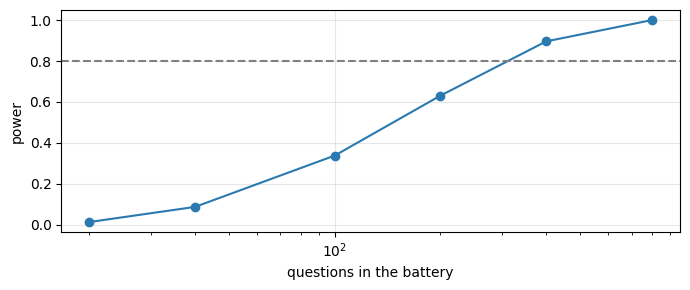

In [12]:
from scipy.stats import binomtest
rng = np.random.default_rng(1)

def power(n_q, p_ab=0.05, p_ba=0.12, sims=1000):
    hits = 0
    for _ in range(sims):
        ab, ba, _ = rng.multinomial(n_q, [p_ab, p_ba, 1 - p_ab - p_ba])
        if ab + ba and binomtest(int(ba), int(ab + ba), 0.5).pvalue < 0.05:
            hits += 1
    return hits / sims

sizes = [20, 40, 100, 200, 400, 800]
pw = [power(n) for n in sizes]
for n_q, p in zip(sizes, pw):
    print(f"{n_q:4d} questions: a true 7-point improvement is detected {p:5.0%} of the time")
fig, ax = plt.subplots(figsize=(7, 3)); ax.plot(sizes, pw, "o-", color="#2a7ab0"); ax.axhline(0.8, ls="--", color="grey")
ax.set_xscale("log"); ax.set_xlabel("questions in the battery"); ax.set_ylabel("power"); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

The standard target is 80% power. A forty-question battery detects a seven-point improvement far less
often than that, so differences of a few questions on a battery this size must be reported as
*"no detectable difference"*, not as a win. Two practical rules follow: **grow the battery** whenever a
decision hangs on a small difference (production traffic is the best source of new questions, which is
exactly what module 08 automates), and **look at the failures one by one**, because a handful of understood
failures teaches more than a decimal point of accuracy.

## 8. Before and after, on questions the fix has not seen

We now repair the failures that set 1 shows, and measure on both sets. Two fixes, both found by reading set 1:

1. **Entity guard**: a question naming a turbine that does not exist (`HV99`) is refused. This addresses
   a trap.
2. **Vocabulary expansion**: add the handbook's own words next to the user's (*boats* with *vessels*,
   *qualification* with *certificate*, *ashore* with *onshore export*...), taken from the set 1 misses.

The honest test is **set 2**, written after the fixes were designed: it was not used to choose them.

In [13]:
SYN = {"boats": "vessels", "boat": "vessel", "qualification": "certificate", "ashore": "onshore export", "alone": "lone",
       "blackout": "grid loss", "dolphin": "marine mammal", "autumn": "october march migration", "injury": "injury near miss"}
def expand(question):
    extra = [v for k, v in SYN.items() if re.search(rf"\b{k}\b", question, re.I)]
    return question + " " + " ".join(extra)

B_fix = build_system(hybrid, lambda q, e: bm25.scores(e).max() < 1.0 and sem(e).max() < 0.30, expand=expand, entity_guard=True)
A_fix = build_system(bm25.scores, lambda q, e: bm25.scores(e).max() < 1.0, expand=expand, entity_guard=True)

systems = {"A": A, "A+fix": A_fix, "B": B, "B+fix": B_fix}
for label, battery in [("set 1 (used to design the fixes)", SET1), ("set 2 (written after, held out)", SET2)]:
    res = {n: run_all(s, battery) for n, s in systems.items()}
    m = metrics(res, battery)
    print(label)
    print(f"{'system':>8s}{'correct':>9s}{'of':>4s}{'hit@1':>8s}{'MRR':>7s}{'refusal rec':>13s}")
    for n, v in m.items():
        print(f"{n:>8s}{int(round(v['correct'] * len(battery))):9d}{len(battery):4d}{v['hit1']:8.2f}{v['mrr']:7.2f}{v['ref_rec']:13.2f}")
    print()

set 1 (used to design the fixes)
  system  correct  of   hit@1    MRR  refusal rec
       A       15  20    0.81   0.90         0.50
   A+fix       18  20    0.94   0.96         0.75
       B       16  20    0.94   0.97         0.25
   B+fix       18  20    1.00   1.00         0.50



set 2 (written after, held out)
  system  correct  of   hit@1    MRR  refusal rec
       A       10  20    0.62   0.70         0.00
   A+fix       12  20    0.69   0.75         0.25
       B       12  20    0.75   0.86         0.00
   B+fix       14  20    0.81   0.90         0.25



Compare the two blocks the way the real evaluation did (set 1 before and after its fixes, then set 2
written afterwards). The gain on **set 1** is partly an artefact: we designed the fixes by looking at it
(A goes from 15 to 18 correct, B from 16 to 18). The **set 2** numbers are the honest ones: both systems gain
two questions there too (A 10 to 12, B 12 to 14), so the repair generalised at least a little. But two
questions out of twenty is inside the noise of section 7, and most of the remaining failures are untouched:
the traps without an identifier to check (*stock price*, *how many people work on the farm*) and paraphrases
whose words are not in our small synonym list. Whatever the figures say, state them as they are. A fix that
helps set 1 and does nothing on set 2 has only memorised set 1.

For scale, the real wind-farm agent evaluated this way went from **5 of 15** to **13 of 15** correct on
its first set after fixes, and on a second set of 20 questions written afterwards (with traps such as a
turbine that does not exist and a result never computed) from **12 of 20** to **20 of 20**. The second set
mattered more than the first: it is what showed the fixes were real.

## Exercises

1. Add five questions of your own to set 2 (one trap, two paraphrases, one identifier, one direct). Re-run
   section 8. Does the conclusion change?
2. Add `10 minutes?` style tolerance to a pattern and break another: write one pattern that is too weak
   and one too strict, and find them with the disagreement list of section 4.
3. In `faithfulness`, change the 0.6 support threshold to 0.3 and to 0.9. Which of the six samples change
   verdict, and which setting would you use for a safety handbook?
4. Change `p_ab` and `p_ba` in `power` to a 3-point improvement. How large must the battery be now?